# 24 · The geometry model in OpenVSP: from a sizing result to an outer mold line, renders and an aerodynamic cross-check

The sizing never needs a CAD-level shape: surfaces are area, aspect ratio and taper; bodies are length and section. But people need to *see* the
aircraft, packaging and structures need a shape, and the aerodynamics deserves a check by an independent tool. `export/openvsp/` (about 1,560 lines,
plan 031) builds the aircraft in **OpenVSP** (NASA's parametric geometry tool) through its Python API:

| Module | What |
|---|---|
| `snapshot.py` | `GeometrySnapshot`: the numeric geometry of a solved aircraft, plain floats only, the only input the export reads |
| `model.py` | the OpenVSP model tree (fuselage, wing, fairing, tails, nacelles on a tilt hinge, rotors), `.vsp3`, STEP and STL exports, nacelle Modes |
| `render.py` | off-screen renders of the exported STL with PyVista |
| `aero.py` | VSPAERO (vortex lattice / panel) sweeps and OpenVSP's parasite-drag build-up, as a cross-check of AeroSandbox |
| `structure.py`, `fe_wing.py`, `structure_check.py` | the internal structure and the finite-element check (tutorial 25) |

The rule (`docs/CODING_CONVENTIONS.md`): **nothing in the sizing imports this package**. OpenVSP is a downstream consumer of a solved, numeric design,
never part of a solve.

**Requires** the OpenVSP Python API (installed into `.venv` from the OpenVSP 3.53.1 distribution; `uv sync` removes it, use `--inexact`) and the
`geometry` dependency group (PyVista). Outputs go to `output/tutorials/openvsp/` (not committed).

**Run time:** about a minute (four OpenVSP builds and exports, one VSPAERO sweep).

In [1]:
from tutorial_helpers import *
import numpy as onp
import inspect, re
from dataclasses import replace, fields
from IPython.display import Image, display
import openvsp as vsp
from examples.halo_sizing import HaloRequirements, HaloAssumptions, solve_halo_sizing, build_halo_aircraft
requirements = HaloRequirements()
reference = cached("reference_scholz", lambda: solve_halo_sizing(requirements, replace(HaloAssumptions(), aerodynamics_model="scholz")))
counts = {name: whole for name, (relaxed, whole) in reference.machine_units.items()}
assumptions = replace(HaloAssumptions(), aerodynamics_model="scholz", count_units_motor=counts["motor"],
                      count_units_generator=counts["generator"])
directory = output_dir / "openvsp"
directory.mkdir(parents=True, exist_ok=True)
print(f"OpenVSP {vsp.GetVSPVersion()}; outputs in {directory}")

OpenVSP OpenVSP 3.53.1; outputs in C:\Users\alexa\Documents\Chasing Amber\halo-tutorials\output\tutorials\openvsp


## 1. The firewall

Check the rule directly: no module outside `export/` imports OpenVSP or the export package.

In [2]:
offenders = []
for path in (repo_root / "src" / "aircraft_closure").rglob("*.py"):
    if "export" in path.parts:
        continue
    text = path.read_text(encoding="utf-8")
    if re.search(r"^\s*(import openvsp|from openvsp|from aircraft_closure\.export)", text, flags=re.M):
        offenders.append(path.name)
check("nothing in the sizing code imports OpenVSP or the export package", not offenders)

PASS  nothing in the sizing code imports OpenVSP or the export package


## 2. The snapshot: numeric geometry of a solved aircraft

`GeometrySnapshot` holds plain floats (x aft, y right, z up, metres, origin at the fuselage nose): a `BodySnapshot` fuselage (super-ellipse stations),
`SurfaceSnapshot` wing and tails (span, root and tip chords, leading-edge position, airfoil), a `NacelleSnapshot` (dimensions, spindle position, mast),
a `RotorSnapshot` (radius, blades, solidity, twist) and an optional dorsal wing fairing. Nothing in it can be symbolic, so the export can never take part
in a solve.

The repository's own example, `halo_plan027_snapshot()`, is a fixed drawing of the plan 027 design. Here we build one **from a sizing result**, so the
picture follows the design. Sized quantities come from the result; shape choices the sizing does not make (wing taper for looks, nacelle shape, V-tail
proportions and position, fuselage profile) follow the Halo stills, as in `halo_plan027_snapshot` (whose docstring lists them):

In [3]:
from aircraft_closure.export.openvsp.snapshot import (GeometrySnapshot, SurfaceSnapshot, NacelleSnapshot, RotorSnapshot, halo_fuselage,
                                                      dorsal_wing_fairing, v_tail_equivalent, halo_plan027_snapshot)

def snapshot_from_result(result, assumptions, taper_wing=0.6):
    """A GeometrySnapshot of a sized Halo: sized wing area, span, position, rotor and tail areas; Halo-like shape choices elsewhere."""
    d = result.design
    aircraft = build_halo_aircraft(d, requirements, assumptions)
    wing = aircraft.wing
    span_m, area_m2 = float(wing.span_m()), float(wing.area_m2)
    chord_root_m = 2 * area_m2 / (span_m * (1 + taper_wing))
    x_quarter_chord_m = float(wing.x_le_root_m) + 0.25 * area_m2 / span_m          # keep the sized quarter-chord line
    height_m, width_m = assumptions.height_fuselage_m, assumptions.diameter_fuselage_m
    wing_snapshot = SurfaceSnapshot(span_m=span_m, chord_root_m=chord_root_m, chord_tip_m=taper_wing * chord_root_m,
                                    x_le_root_m=x_quarter_chord_m - 0.25 * chord_root_m, z_m=float(wing.z_m),
                                    thickness_to_chord=assumptions.thickness_to_chord_wing, camber=0.02, fraction_chord_sweep=0.25)
    return GeometrySnapshot(
        fuselage=halo_fuselage(length_m=assumptions.length_fuselage_m, width_m=width_m, height_m=height_m),
        wing=wing_snapshot,
        wing_fairing=dorsal_wing_fairing(wing_snapshot, z_top_fuselage_m=0.5 * height_m, width_fuselage_m=width_m),
        nacelle=NacelleSnapshot(length_m=assumptions.length_nacelle_m * 1.24, width_m=0.65, height_m=1.0, fraction_chord_spindle=0.25,
                                offset_z_spindle_m=0.0, length_mast_m=assumptions.length_mast_m, offset_nose_m=0.35),
        rotor=RotorSnapshot(radius_m=float(result.radius_rotor_m), count_blades=assumptions.count_blades, solidity=float(d.solidity)),
        v_tail=v_tail_equivalent(area_horizontal_tail_m2=float(d.area_horizontal_tail_m2), area_vertical_tail_m2=float(d.area_vertical_tail_m2),
                                 aspect_ratio=3.27, taper_ratio=0.5, sweep_le_deg=40.0, x_le_root_m=9.1, z_m=0.85, thickness_to_chord=0.12),
    )

snapshot = snapshot_from_result(reference, assumptions)
plan027 = halo_plan027_snapshot()
print(f"{'':<26}{'this design':>14}{'plan 027 drawing':>18}")
for label, f in (("wing span [m]", lambda s: s.wing.span_m), ("wing root chord [m]", lambda s: s.wing.chord_root_m),
                 ("rotor radius [m]", lambda s: s.rotor.radius_m), ("solidity", lambda s: s.rotor.solidity),
                 ("V-tail span [m]", lambda s: s.v_tail.span_m), ("V-tail dihedral [deg]", lambda s: s.v_tail.dihedral_deg)):
    print(f"{label:<26}{f(snapshot):14.3f}{f(plan027):18.3f}")
x_spindle_m, y_spindle_m, z_spindle_m = snapshot.spindle_xyz_m()
clearance_m = y_spindle_m - snapshot.rotor.radius_m - assumptions.diameter_fuselage_m / 2
print(f"spindle at ({x_spindle_m:.2f}, {y_spindle_m:.2f}, {z_spindle_m:.2f}) m; rotor-to-fuselage clearance {clearance_m:.2f} m "
      f"(the sizing's rotor-radius limit keeps {assumptions.clearance_rotor_fuselage_m} m)")
check("the rotor clears the fuselage by the sizing's clearance", clearance_m >= assumptions.clearance_rotor_fuselage_m - 1e-3)

                             this design  plan 027 drawing
wing span [m]                     11.927            11.441
wing root chord [m]                2.436             2.337
rotor radius [m]                   4.825             4.582
solidity                           0.060             0.089
V-tail span [m]                    5.104             4.198
V-tail dihedral [deg]             35.821            33.685
spindle at (5.11, 5.96, 1.20) m; rotor-to-fuselage clearance 0.30 m (the sizing's rotor-radius limit keeps 0.3 m)
PASS  the rotor clears the fuselage by the sizing's clearance


The V-tail carries the sized horizontal and vertical tail areas by the classic **equal-projected-area rule** (`v_tail_equivalent`: total panel area = $S_h + S_v$,
dihedral = $\arctan\sqrt{S_v/S_h}$), so its plan and side projections reproduce the two tails the sizing used. The rotor clearance printed above is exactly
the sizing's `rotor_radius_m` margin (binding in tutorial 19's list): the rotor is as big as the span allows.

The same snapshot also gives an AeroSandbox airplane (`snapshot.to_asb()`), so OpenVSP and AeroSandbox analyses below see identical geometry.

## 3. The OpenVSP model

`build_openvsp_model(snapshot, angle_nacelle_deg)` clears the model and builds the tree (it follows the user-supplied tiltrotor skeleton):

```
Fuselage (smoothly skinned)
|- WingFairing (dorsal fairing)
|- Wing
|  `- NacelleTilt (a Hinge about y at the conversion spindle)
|     `- Nacelle (body)
|        `- Rotor (Propeller)
|           `- RotorTipPath (Auxiliary: clearance envelope)
`- VTail (or HorizontalTail and VerticalTail)
```

The whole nacelle tilts about the spindle (the Halo's arrangement), so one hinge angle moves nacelle, rotor and tip-path envelope together. Look at what
was built:

In [4]:
from aircraft_closure.export.openvsp.model import build_openvsp_model, export_outer_mold_line
with quiet_output():
    geoms = build_openvsp_model(snapshot, angle_nacelle_deg=90.0)
for name, geom_id in geoms.items():
    parent = vsp.GetGeomParent(geom_id)
    print(f"{name:<14} {vsp.GetGeomTypeName(geom_id):<12} parent: {vsp.GetGeomName(parent) if parent else '-'}")
hinge = geoms["NacelleTilt"]
print("\nhinge angle:", vsp.GetParmVal(vsp.FindParm(hinge, "JointRotate", "Hinge")), "deg;  rotor diameter:",
      round(vsp.GetParmVal(vsp.FindParm(geoms["Rotor"], "Diameter", "Design")), 3), "m")
wing_span = vsp.GetParmVal(vsp.FindParm(geoms["Wing"], "TotalSpan", "WingGeom"))
print(f"wing total span in OpenVSP: {wing_span:.3f} m (snapshot {snapshot.wing.span_m:.3f} m)")
check("the OpenVSP wing span equals the snapshot's", abs(wing_span - snapshot.wing.span_m) < 1e-3)

Fuselage       Fuselage     parent: 
Wing           Wing         parent: Fuselage
WingFairing    Fuselage     parent: Fuselage
VTail          Wing         parent: Fuselage
NacelleTilt    Hinge        parent: Wing
Nacelle        Fuselage     parent: NacelleTilt
Rotor          Propeller    parent: Nacelle
RotorTipPath   Auxiliary    parent: Rotor

hinge angle: 90.0 deg;  rotor diameter: 9.65 m
wing total span in OpenVSP: 11.927 m (snapshot 11.927 m)
PASS  the OpenVSP wing span equals the snapshot's


Every value is set through `vsp.SetParmVal` by name; the module raises if a parameter name is not found, so an OpenVSP version change fails loudly instead
of silently drawing the wrong thing. The rotor blade gets a constant chord from the solidity ($c/R = \sigma\pi/B$) and linear twist; it is for display and
clearance, not rotor analysis.

## 4. Exports and renders

`export_outer_mold_line` writes STEP and STL files at each nacelle angle (rebuilding the model each time: OpenVSP 3.53.1 keeps the first tessellation of hinge
children otherwise) and a `.vsp3` with **Modes** (hover, conversion, cruise presets of the hinge angle) for the OpenVSP GUI:

In [5]:
import time
time_start_s = time.perf_counter()
with quiet_output():
    paths = export_outer_mold_line(snapshot, directory / "outer_mold_line")
print(f"exported in {time.perf_counter() - time_start_s:.0f} s")
for key, path in paths.items():
    print(f"   {str(key):<26} {path.name:<34} {path.stat().st_size / 1e6:6.2f} MB")

exported in 15 s
   ('stl', 90.0)              halo_nacelle90.stl                   4.48 MB
   ('step', 90.0)             halo_nacelle90.stp                  41.40 MB
   ('stl_airframe', 90.0)     halo_nacelle90_airframe.stl          3.64 MB
   ('stl_rotors', 90.0)       halo_nacelle90_rotors.stl            0.84 MB
   ('stl', 45.0)              halo_nacelle45.stl                   4.47 MB
   ('step', 45.0)             halo_nacelle45.stp                  41.89 MB
   ('stl_airframe', 45.0)     halo_nacelle45_airframe.stl          3.64 MB
   ('stl_rotors', 45.0)       halo_nacelle45_rotors.stl            0.84 MB
   ('stl', 0.0)               halo_nacelle00.stl                   4.47 MB
   ('step', 0.0)              halo_nacelle00.stp                  41.83 MB
   ('stl_airframe', 0.0)      halo_nacelle00_airframe.stl          3.64 MB
   ('stl_rotors', 0.0)        halo_nacelle00_rotors.stl            0.84 MB
   vsp3                       halo.vsp3                            0.53 MB


C:\Users\alexa\Documents\Chasing Amber\halo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


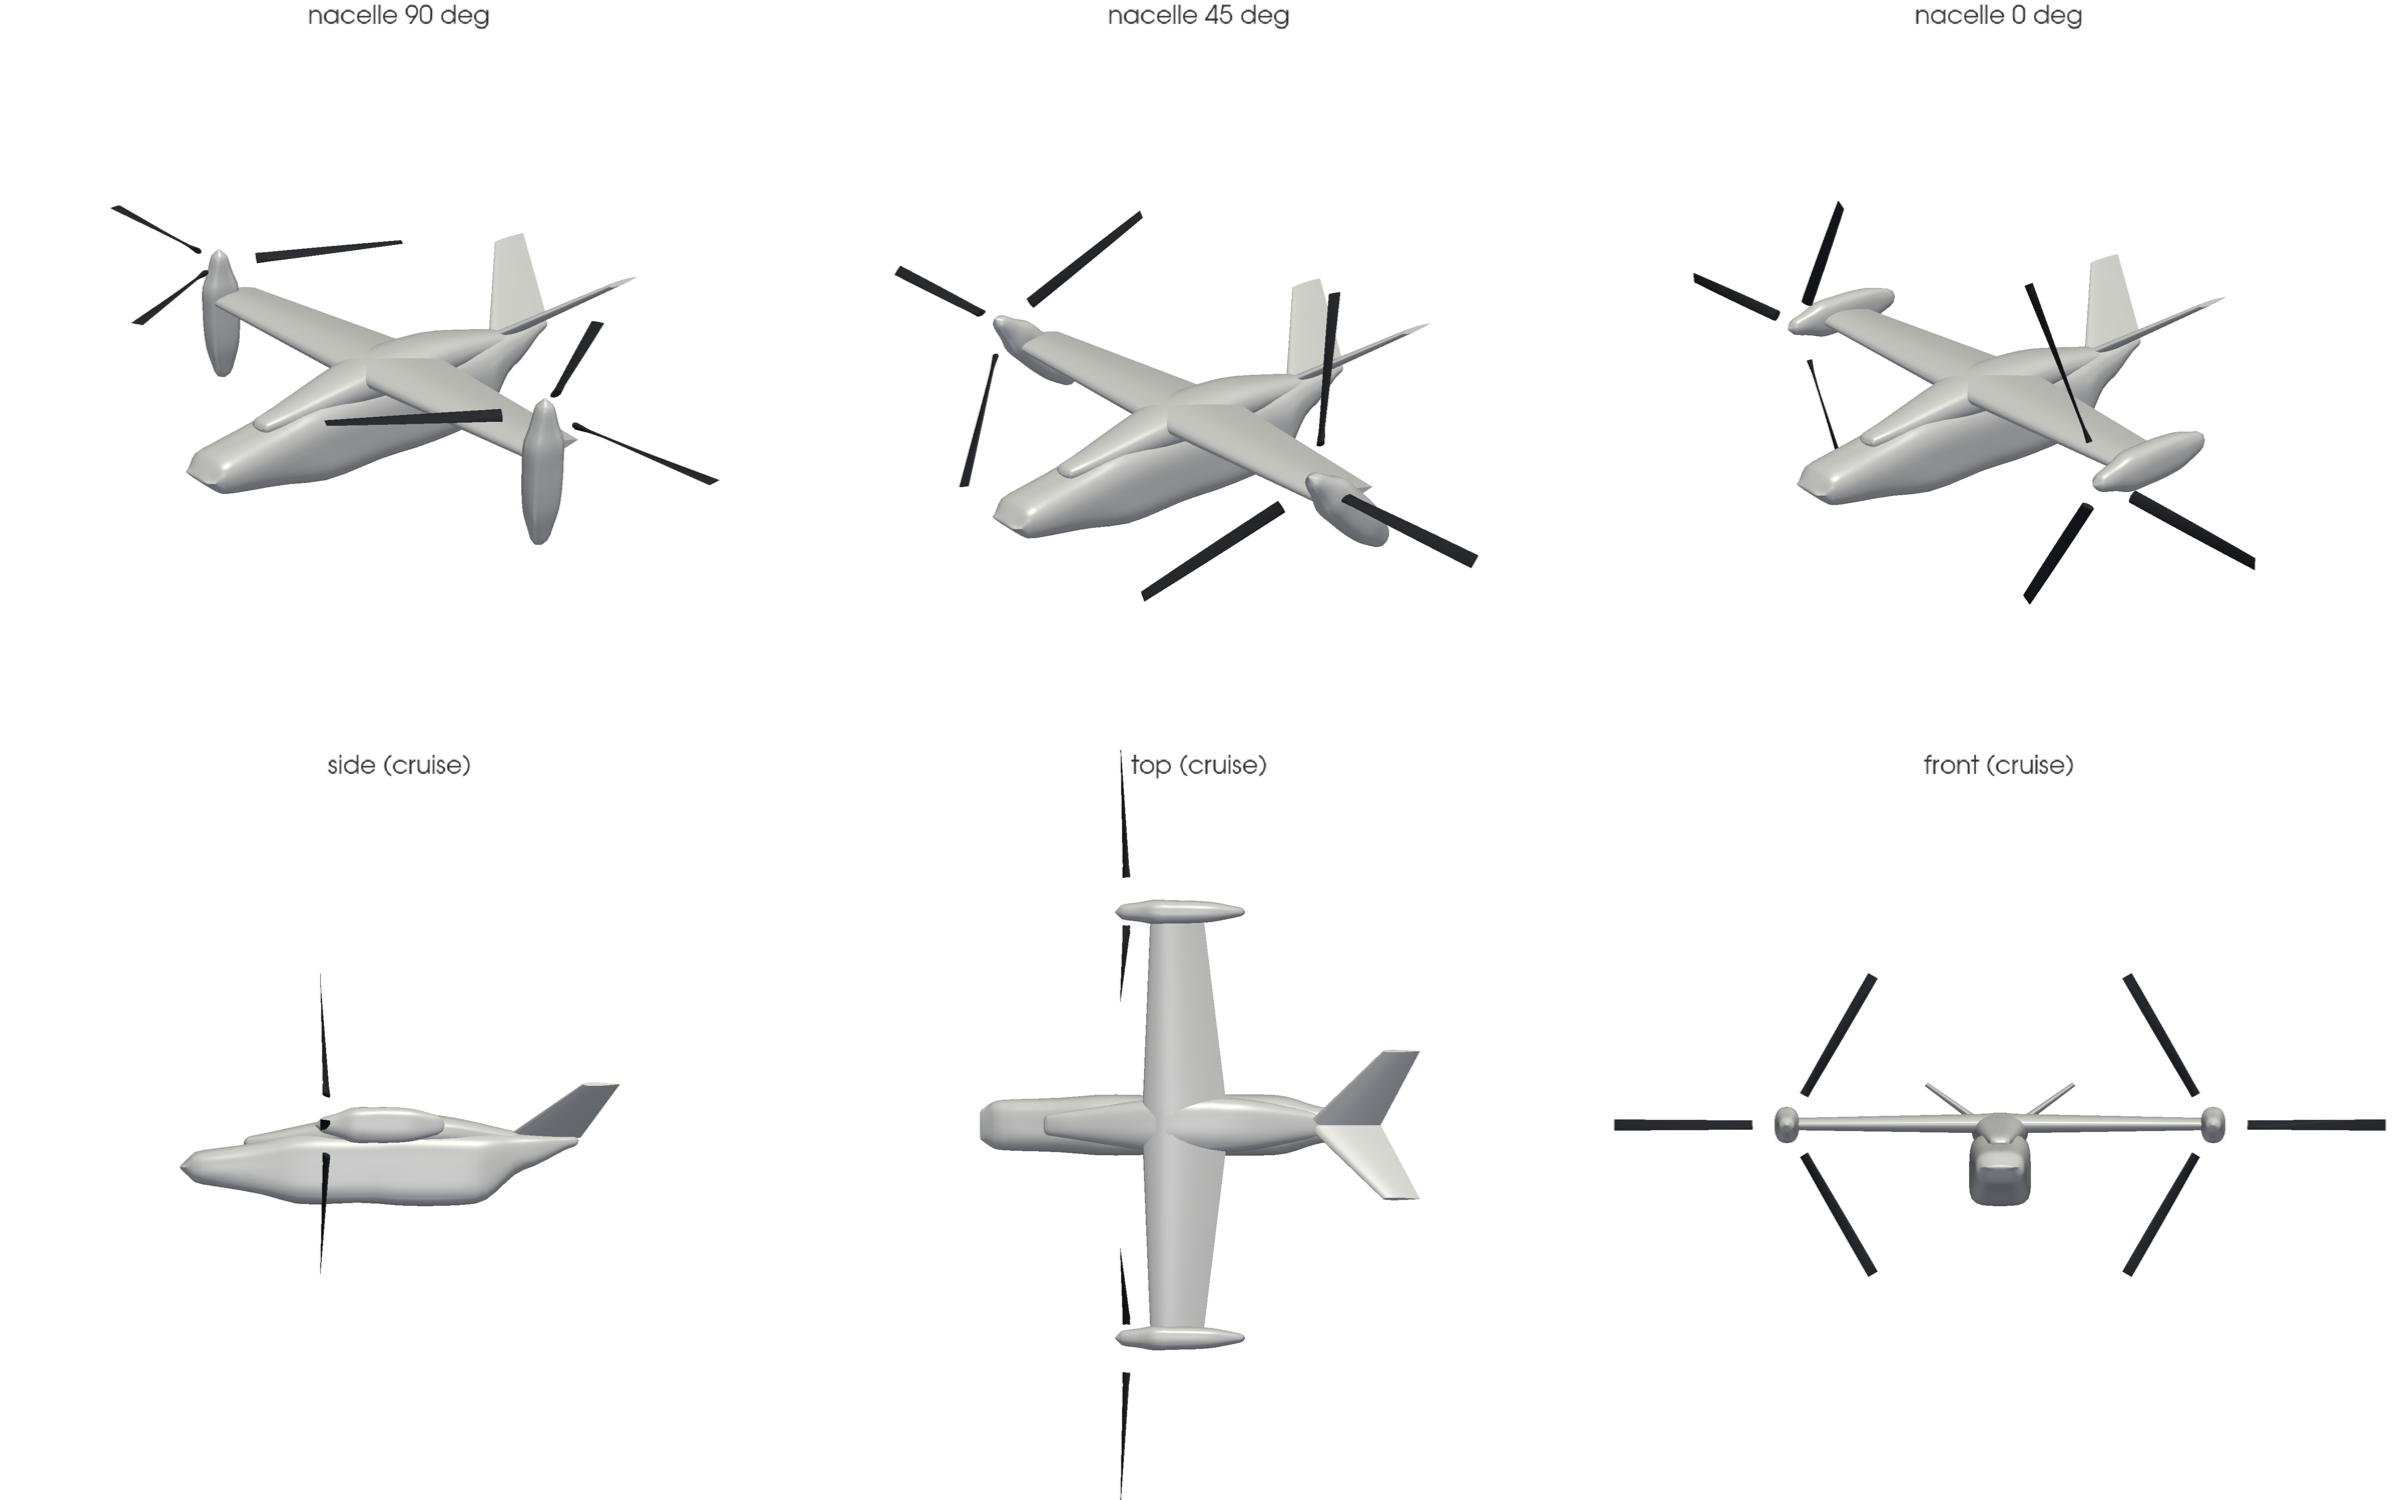

In [6]:
from aircraft_closure.export.openvsp.render import render_sheet, views_orthographic, views_perspective
angles = sorted({key[1] for key in paths if isinstance(key, tuple)}, reverse=True)
views = [(f"nacelle {a:.0f} deg", paths[("stl_airframe", a)], paths[("stl_rotors", a)], views_perspective) for a in angles]
views += [(f"{view[0]} (cruise)", paths[("stl_airframe", 0.0)], paths[("stl_rotors", 0.0)], view) for view in views_orthographic]
with quiet_output():
    render_sheet(views, directory / "views.png")
apply_style()            # PyVista and AeroSandbox drawing change matplotlib's global style
display(Image(filename=str(directory / "views.png"), width=1000))

Open `output/tutorials/openvsp/outer_mold_line/halo.vsp3` in the OpenVSP GUI to inspect it interactively; the Modes menu switches the nacelle angle.

## 5. Cross-checking the aerodynamics

OpenVSP brings two analyses AeroSandbox does not: **VSPAERO** (vortex lattice and panel methods) and a component **parasite-drag build-up**. Running both on the
same snapshot as AeroSandbox gives an independent check of the sizing's aerodynamics (`examples/halo_aero_compare.py` does the full comparison; checks only,
nothing feeds the sizing).

**Profile drag by component** at the 210 kt / 10,000 ft speed requirement, OpenVSP's build-up against AeroBuildup:

In [7]:
from aircraft_closure.export.openvsp.aero import run_parasite_drag, run_vspaero_sweep
from examples.halo_aero_compare import aerosandbox_profile_by_component, aerosandbox_polars, slopes
altitude_m, velocity_m_s = 10000 * u.foot, 210 * u.knot
with quiet_output():
    parasite = run_parasite_drag(snapshot, altitude_m, velocity_m_s)
airplane = snapshot.to_asb()
op_zero = asb.OperatingPoint(atmosphere=asb.Atmosphere(altitude=altitude_m), velocity=velocity_m_s, alpha=0.0)
profile_asb = aerosandbox_profile_by_component(airplane, op_zero)
names_asb = {"Fuselage": ["fuselage"], "Wing": ["wing"], "Nacelle": ["nacelle_right", "nacelle_left"], "WingFairing": ["wing_fairing"], "VTail": ["v_tail"]}
print(f"{'component':<12}{'OpenVSP Swet m2':>16}{'FF':>6}{'OpenVSP CD0':>13}{'AeroBuildup':>13}")
for label, area, ff, cd0 in zip(parasite.labels, parasite.area_wetted_m2, parasite.form_factor, parasite.cd0):
    asb_cd0 = sum(profile_asb.get(n, 0.0) for n in names_asb.get(label, []))
    print(f"{label:<12}{area:16.1f}{ff:6.2f}{1e4 * cd0:11.1f} ct{1e4 * asb_cd0:11.1f} ct")
print(f"{'total':<12}{'':>22}{1e4 * parasite.cd0_total:11.1f} ct{1e4 * sum(profile_asb.values()):11.1f} ct")

component    OpenVSP Swet m2    FF  OpenVSP CD0  AeroBuildup
Fuselage                48.7  1.17       55.4 ct       59.1 ct
Wing                    41.0  1.62       84.0 ct       61.4 ct
Nacelle                 15.5  1.30       23.5 ct       38.5 ct
WingFairing             11.8  1.13       13.6 ct       37.4 ct
VTail                   15.5  1.32       26.8 ct       18.0 ct
total                                   203.4 ct      214.4 ct


(1 count = 0.0001 of $C_D$.) Both are clean-component build-ups (no excrescence, gear or interference factors beyond each tool's own), so they should agree
roughly, and neither is a calibrated aircraft drag (tutorial 13's NDARC calibration adds about 27 %).

**Lift curve and induced drag**: VSPAERO's vortex lattice on the lifting surfaces ("thin") against AeroSandbox's vortex lattice, at Mach 0.33:

In [8]:
alpha_deg = onp.array([-2.0, 0.0, 2.0, 4.0, 6.0])
atmosphere = asb.Atmosphere(altitude=altitude_m)
mac_m = snapshot.wing.mean_aerodynamic_chord_m()
reynolds = float(atmosphere.density() * velocity_m_s * mac_m / atmosphere.dynamic_viscosity())
xyz_ref_m = (snapshot.wing.x_le_root_m + 0.25 * snapshot.wing.chord_root_m, 0.0, snapshot.wing.z_m)
time_start_s = time.perf_counter()
with quiet_output():
    vspaero = run_vspaero_sweep(snapshot, directory / "vspaero", "thin", alpha_deg, mach=float(velocity_m_s / atmosphere.speed_of_sound()),
                                reynolds_cref=reynolds, xyz_ref_m=xyz_ref_m, count_cpu=4)
print(f"VSPAERO sweep: {time.perf_counter() - time_start_s:.0f} s")
op = asb.OperatingPoint(atmosphere=atmosphere, velocity=velocity_m_s, alpha=alpha_deg)
buildup, vlm = aerosandbox_polars(airplane, op, xyz_ref_m)
aspect_ratio = snapshot.wing.span_m**2 / airplane.s_ref
rows = {"VSPAERO thin (VLM)": slopes(vspaero.alpha_deg, vspaero.cl, vspaero.cm, vspaero.cdi_wake, aspect_ratio),
        "AeroSandbox VLM": slopes(alpha_deg, vlm["cl"], vlm["cm"], vlm["cdi"], aspect_ratio),
        "AeroSandbox AeroBuildup": slopes(alpha_deg, buildup["cl"], buildup["cm"], buildup["cdi"], aspect_ratio)}
print(f"{'':<26}{'CL_alpha /deg':>14}{'CL at 0':>9}{'Oswald e':>10}")
for label, s in rows.items():
    print(f"{label:<26}{s['cl_alpha_per_deg']:14.4f}{s['cl_zero']:9.3f}{s['oswald']:10.3f}")
check("VSPAERO and AeroSandbox VLM lift slopes agree within 10 %",
      abs(rows["VSPAERO thin (VLM)"]["cl_alpha_per_deg"] / rows["AeroSandbox VLM"]["cl_alpha_per_deg"] - 1) < 0.10)

VSPAERO sweep: 8 s


                           CL_alpha /deg  CL at 0  Oswald e
VSPAERO thin (VLM)                0.0894    0.155     1.137
AeroSandbox VLM                   0.0857    0.145     1.045
AeroSandbox AeroBuildup           0.0979    0.246     0.823
PASS  VSPAERO and AeroSandbox VLM lift slopes agree within 10 %


Two independent vortex-lattice codes on the same geometry should agree closely on lift slope and span efficiency; AeroBuildup includes the fuselage and its
own empirical slopes, so it differs more. This is the "validate what exists" first step of the README's aerodynamics work package.

## Limits and next steps

**What it can't do**

- **No geometry in the loop**: the sizing never sees the OpenVSP shape; aesthetic choices (wing taper, V-tail placement, fuselage profile) are drawn but not sized,
  and the V-tail here sits about 0.7 m ahead of the sizing's tail position.
- **The rotor blade is for display and clearance only** (constant chord, linear twist).
- **VSPAERO with thick bodies** ("mixed", "panel") gives unreliable induced drag in VSPAERO 7, so induced drag is compared from the "thin" model only.
- **One OpenVSP version is assumed** (3.53.1); parameter names are checked so a mismatch fails loudly.

**What's next:** size the V-tail directly (the trim model's cos Γ hook is ready); feed the drawn layout's dimensions back as sizing inputs where they matter;
rotor-wing interaction with VSPAERO's propeller modelling (download in hover, blown wing in cruise); targeted CFD on the OpenVSP geometry later.

## Summary

- `GeometrySnapshot` is the numeric firewall between the sizing and OpenVSP: plain floats from a solved design, plus stated shape choices.
- `build_openvsp_model` builds the tree with a tilt hinge per nacelle; `export_outer_mold_line` writes STEP, STL and a `.vsp3` with nacelle Modes; `render.py`
  draws sheets off-screen.
- VSPAERO and OpenVSP's parasite-drag tool cross-check AeroSandbox on identical geometry; checks only.

## Check yourself

<details><summary>1. Why does the export read a snapshot of floats instead of the sizing's `Aircraft` object?</summary>

The `Aircraft` may hold Opti variables and its geometry is the sizing's simplified one. A snapshot of floats guarantees the export can never take part in a solve, adds the shape detail the sizing does not need, and keeps the dependency one-way (sizing results flow into the export, never back).
</details>

<details><summary>2. VSPAERO's lift slope is 8 % higher than AeroSandbox's VLM on the same snapshot. What do you check first?</summary>

That both see the same reference area and span (the snapshot's wing, not the tapered drawing versus the sizing's constant chord), the same Mach, and the same lifting surfaces (the "thin" set: wing and tails), then the panel resolution of each code.
</details>

In [9]:
check_summary()

4 of 4 checks passed
